### Lấy mẫu ngẫu nhiên từ dataset `loan.csv`

Dưới đây là list các cách phổ biến dùng để lấy mẫu dữ liệu từ cơ bản cho các dataset nhỏ, đến các công cụ thường được các Data Scientist dùng khi đọc dataset cực lớn.

1. `pd.read_csv()`      đọc toàn bộ dữ liệu vào RAM, phù hợp với dataset nhỏ hoặc vừa.
2. `df.sample()`        dùng để lấy mẫu ngẫu nhiên khi đã có `df`, thường được dùng với `pd.read_csv()`.
3. `chunksize`          tiết kiệm RAM bằng cách đọc dữ liệu theo từng phần (chunk).
4. `Reservoir Sampling` lấy mẫu ngẫu nhiên chuẩn trên các dataset rất lớn mà không cần lưu toàn bộ dữ liệu trong bộ nhớ.
5. `DuckDB / Polars`    công cụ xử lý dữ liệu lớn với hiệu năng cao.
6. `Spark`              xử lý dữ liệu cực lớn trên hệ thống phân tán.

Trong bài này vì dataset `loan.csv` có kích thước khoảng 1gb nên dùng `pd.read_csv` và `df.sample` là vừa đủ.

In [2]:
import pandas as pd

df = pd.read_csv("../../loan.csv")
df_sample = df.sample(n=1000, random_state=2412)

C:\Users\bphuy\AppData\Local\Temp\ipykernel_16212\2910129749.py:3: DtypeWarning: Columns (19: desc, 47: next_pymnt_d, 55: verification_status_joint, 112: sec_app_earliest_cr_line, 123: hardship_type, 124: hardship_reason, 125: hardship_status, 128: hardship_start_date, 129: hardship_end_date, 130: payment_plan_start_date, 133: hardship_loan_status, 139: debt_settlement_flag_date, 140: settlement_status, 141: settlement_date) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../../loan.csv")


### EDA - Exploratory Data Analysis

1. Xem dữ liệu (`head()`, `tail()`)
2. Xem kích thước dataset (`shape`)
3. Xem kiểu dữ liệu (`info()`)
4. Thống kê tỷ lệ missing
5. Xem các cột hằng số hoặc có quá ít giá trị unique
6. Phân loại cột thành `numerical` và `categorical`
7. Xác định biến mục tiêu (target)
8. Chọn các cột quan trọng để phân tích
9. Quan sát biểu đồ:
    - Histogram
    - Boxplot (đối với numerical)
10. Phân tích các cột `categorical`

### Data Preprocessing
11. Xử lý dữ liệu thiếu (missing values)
12. Xử lý outlier (`log1p`)



##### 1. `Xem dữ liệu`

In [3]:
display(df_sample.head())
display(df_sample.tail())

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
1590661,NaN,NaN,16000,16000,16000.0,36 months,10.42,519.44,B,B3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1609217,NaN,NaN,6000,6000,6000.0,36 months,15.05,208.14,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
902066,NaN,NaN,15000,15000,15000.0,36 months,12.74,503.54,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1030445,NaN,NaN,27000,27000,27000.0,36 months,5.32,813.10,A,A1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1265339,NaN,NaN,1600,1600,1600.0,36 months,15.61,55.95,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
816502,NaN,NaN,12000,12000,12000.0,36 months,6.49,367.74,A,A2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
498506,NaN,NaN,10000,10000,10000.0,36 months,10.99,327.34,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1933635,NaN,NaN,20000,20000,20000.0,60 months,10.15,426.42,B,B2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
940345,NaN,NaN,25000,25000,25000.0,60 months,12.59,563.60,C,C2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
815964,NaN,NaN,6000,6000,6000.0,36 months,11.99,199.26,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


##### 2. `Xem kích thước`

In [4]:
df_sample.shape

(1000, 145)

##### 3. `Xem kiểu dữ liệu`

In [5]:
df_sample.info()

<class 'pandas.DataFrame'>
Index: 1000 entries, 1590661 to 815964
Columns: 145 entries, id to settlement_term
dtypes: float64(105), int64(4), str(36)
memory usage: 1.1 MB


##### 4. ` Thống kê missing values`

In [6]:
missing_stats = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": round(df.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

missing_stats.head(20)

,missing_count,missing_pct
id,2260668,100.00
member_id,2260668,100.00
url,2260668,100.00
orig_projected_additional_accrued_interest,2252242,99.63
hardship_amount,2250055,99.53
hardship_dpd,2250055,99.53
hardship_loan_status,2250055,99.53
deferral_term,2250055,99.53
hardship_end_date,2250055,99.53
hardship_status,2250055,99.53


#### Vì số cột có tỉ lệ missing cao (>90%) tương đối nhiều nên xóa hết
Xem các cột có missing value >70%

In [7]:
cols_to_drop = missing_stats[
    missing_stats["missing_pct"] > 70
]

print(f"Số cột sẽ bị xóa: {len(cols_to_drop)}")
display(cols_to_drop)

Số cột sẽ bị xóa: 41


,missing_count,missing_pct
id,2260668,100.00
member_id,2260668,100.00
url,2260668,100.00
orig_projected_additional_accrued_interest,2252242,99.63
hardship_amount,2250055,99.53
hardship_dpd,2250055,99.53
hardship_loan_status,2250055,99.53
deferral_term,2250055,99.53
hardship_end_date,2250055,99.53
hardship_status,2250055,99.53


Xóa các cột đó

In [8]:
df_sample=df_sample.drop(columns=cols_to_drop.index)

#### 5. ` Thống kê unique `
- Thống kê số lượng giá trị unique của từng cột.
- Loại bỏ các cột hằng số (unique = 1).
- Xem xét các cột có số lượng unique rất thấp hoặc quá cao (ID, URL, ...) tuy nhiên hông nên tùy ý xóa các cột unique rất thấp hoặc quá cao nếu chưa biết rõ nghiệp vụ, do đó trong bài này chỉ xóa các cột hằng số.

In [9]:
unique_stats = pd.DataFrame({
    "unique_count": df_sample.nunique()
})

unique_stats.sort_values(
    by="unique_count"
).head(20)

,unique_count
pymnt_plan,1
policy_code,1
next_pymnt_d,1
num_tl_120dpd_2m,1
hardship_flag,1
acc_now_delinq,2
application_type,2
term,2
chargeoff_within_12_mths,2
num_tl_30dpd,2


In [10]:
constant_cols = unique_stats[
    unique_stats["unique_count"] == 1
].index

constant_cols

Index(['pymnt_plan', 'next_pymnt_d', 'policy_code', 'num_tl_120dpd_2m',
       'hardship_flag'],
      dtype='str')

In [11]:
df_sample = df_sample.drop(columns=constant_cols)

##### 6. Phân loại cột thành `numerical` và `categorical`

In [12]:
num_cols = df_sample.select_dtypes(include="number").columns
cat_cols = df_sample.select_dtypes(exclude="number").columns

print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")

Numerical columns: 79
Categorical columns: 20


Xem danh sách cột num & cột cat để rà lại và chỉnh sửa các kiểu dữ liệu

In [13]:
list(num_cols)

['loan_amnt',
 'funded_amnt',
 'funded_amnt_inv',
 'int_rate',
 'installment',
 'annual_inc',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'mths_since_last_delinq',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'out_prncp',
 'out_prncp_inv',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'recoveries',
 'collection_recovery_fee',
 'last_pymnt_amnt',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_coll_amt',
 'tot_cur_bal',
 'open_acc_6m',
 'open_act_il',
 'open_il_12m',
 'open_il_24m',
 'mths_since_rcnt_il',
 'total_bal_il',
 'il_util',
 'open_rv_12m',
 'open_rv_24m',
 'max_bal_bc',
 'all_util',
 'total_rev_hi_lim',
 'inq_fi',
 'total_cu_tl',
 'inq_last_12m',
 'acc_open_past_24mths',
 'avg_cur_bal',
 'bc_open_to_buy',
 'bc_util',
 'chargeoff_within_12_mths',
 'delinq_amnt',
 'mo_sin_old_il_acct',
 'mo_sin_old_rev_tl_op',
 'mo_sin_rcnt_rev_tl_op',
 'mo_sin_rcnt_tl',
 'mort_acc',
 'mths_since_recent_bc',
 'mt

In [14]:
list(cat_cols)

['term',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'verification_status',
 'issue_d',
 'loan_status',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'earliest_cr_line',
 'initial_list_status',
 'last_pymnt_d',
 'last_credit_pull_d',
 'application_type',
 'disbursement_method',
 'debt_settlement_flag']

Phát hiện các cột:
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
là cột date chứ kh phải cat, nên chúng ta sẽ chuyển đổi

In [15]:
date_cols = [
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "last_credit_pull_d"
]

for col in date_cols:
    df_sample[col] = pd.to_datetime(
        df_sample[col],
        errors="coerce"
    )

C:\Users\bphuy\AppData\Local\Temp\ipykernel_16212\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_16212\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_16212\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample[col] = pd.to_datetime(
C:\Users\bphuy\AppData\Local\Temp\ipykernel_16212\2393467789.py:9: UserWarning: Could not infer format, so each element will be parsed individ

##### 7. Xác định biến mục tiêu (target)
Cần trả lời:
- Lãi suất nằm trong khoảng nào?
- Có bị lệch không?
- Có outlier không?

In [16]:
target = "int_rate"
df_sample["int_rate"].describe()

count    1000.00000
mean       13.19032
std         4.95197
min         5.31000
25%         9.70000
50%        12.62000
75%        15.99000
max        30.99000
Name: int_rate, dtype: float64

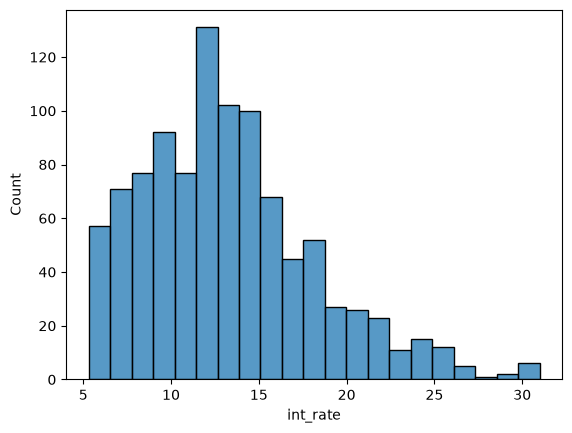

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_sample["int_rate"])

plt.show()

- Lãi suất khoản vay dao động từ 5.31% đến 30.99%.
- 50% khoản vay có lãi suất nằm trong khoảng từ 9.70% đến 15.99%.
- Phân phối có xu hướng lệch phải, cho thấy phần lớn khách hàng có lãi suất trung bình và chỉ một số ít khách hàng có lãi suất rất cao.
- Theo quy tắc IQR, tồn tại một số giá trị outlier ở phía trên. Tuy nhiên các giá trị này vẫn nằm trong phạm vi hợp lý của lãi suất vay.
- Không suất hiện các lỗi nhập liệu như 300%, -999%
---

##### 8. Chọn các feature quan trọng dựa trên
1. Correlation cho các cột số với biến mục tiêu

2. Chọn thêm các cột categorical có ý nghĩa nghiệp vụ: term, grade, sub_grade, verifcation_status, home_ownership

In [18]:
corr_with_target = (
    df_sample[num_cols]
    .corr()["int_rate"]
    .abs()
    .sort_values(ascending=False)
)

corr_with_target.head(20)

int_rate                   1.000000
total_rec_int              0.432868
all_util                   0.278240
bc_open_to_buy             0.276273
percent_bc_gt_75           0.250359
bc_util                    0.241314
revol_util                 0.236331
inq_last_6mths             0.197850
dti                        0.193394
recoveries                 0.192212
inq_last_12m               0.188945
acc_open_past_24mths       0.182450
num_tl_op_past_12m         0.178402
inq_fi                     0.176290
collection_recovery_fee    0.175311
open_il_24m                0.172558
total_bc_limit             0.167875
open_il_12m                0.166543
installment                0.150962
num_actv_rev_tl            0.150366
Name: int_rate, dtype: float64

Các numerical feature được chọn gồm:
- `total_rec_int`
- `all_util`
- `bc_open_to_buy`
- `percent_bc_gt_75`
- `bc_util`

Đây là các feature có độ tương quan tương đối cao với biến mục tiêu `int_rate`.

Ngoài ra, một số feature cũng được lựa chọn dựa trên ý nghĩa nghiệp vụ:

- `annual_inc`
- `loan_amnt`
- `dti`

Kết hợp với các categorical feature:

- `term`
- `grade`
- `sub_grade`
- `verification_status`
- `home_ownership`

Loại bỏ các cột mặc dù có độ tương quan cao nhưng có khả năng gây data leakage:
`total_rec_int`.

In [19]:
# Numerical features
important_num_cols = [
    "all_util",
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "annual_inc",
    "loan_amnt",
    "dti"
]
# Categorical features
important_cat_cols = [
    "term",
    "grade",
    "sub_grade",
    "verification_status",
    "home_ownership"
]
eda_cols = important_num_cols + important_cat_cols + [target]

df_eda = df_sample[eda_cols]

df_eda.head()

,all_util,bc_open_to_buy,percent_bc_gt_75,bc_util,annual_inc,loan_amnt,dti,term,grade,sub_grade,verification_status,home_ownership,int_rate
1590661,73.0,8042.0,50.0,57.9,66000.0,16000,18.62,36 months,B,B3,Verified,MORTGAGE,10.42
1609217,83.0,532.0,100.0,83.4,56000.0,6000,11.74,36 months,C,C4,Not Verified,OWN,15.05
902066,52.0,23226.0,22.2,52.0,70000.0,15000,12.63,36 months,C,C1,Source Verified,OWN,12.74
1030445,NaN,32511.0,33.3,44.5,100000.0,27000,10.63,36 months,A,A1,Not Verified,MORTGAGE,5.32
1265339,NaN,2111.0,0.0,8.2,45000.0,1600,15.23,36 months,D,D1,Verified,MORTGAGE,15.61


##### 9. Quan sát biểu đồ:
    - Histogram

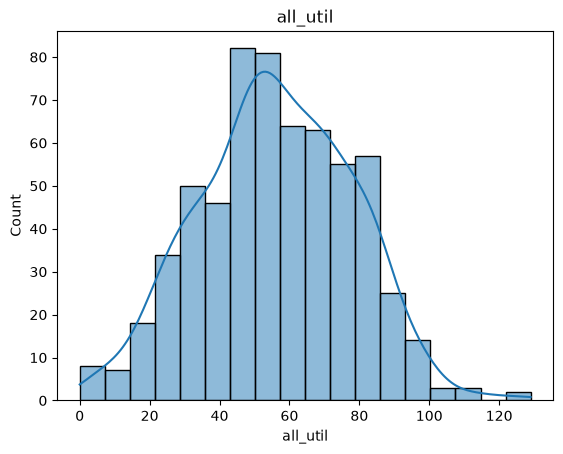

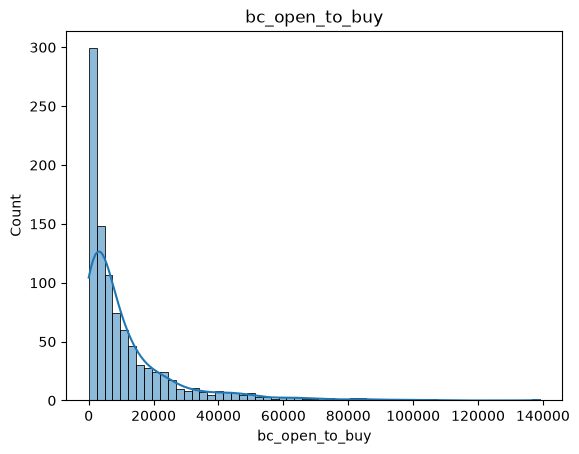

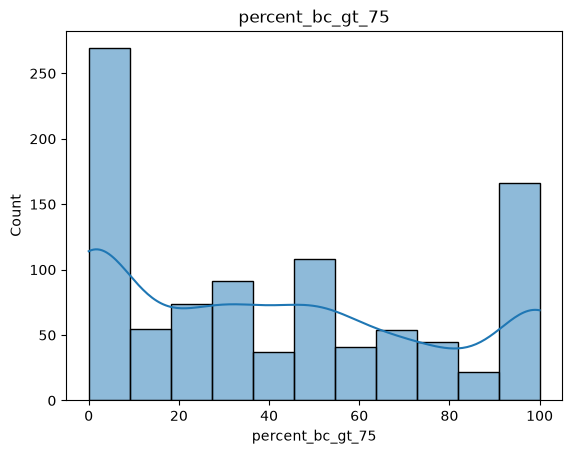

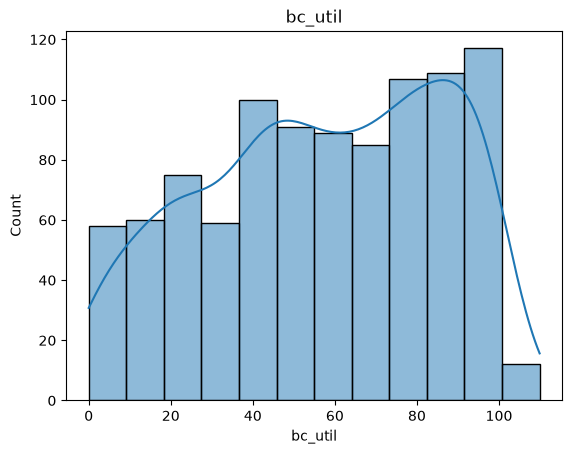

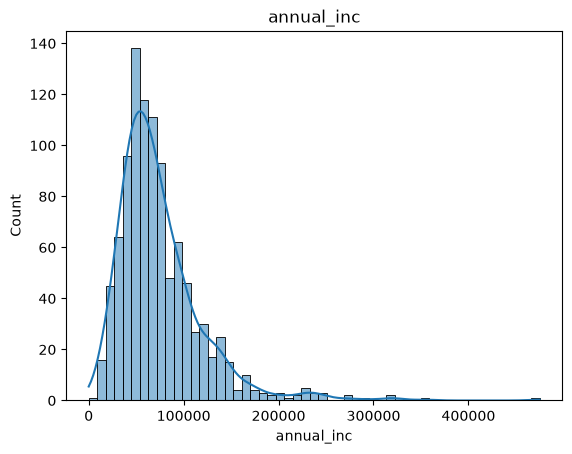

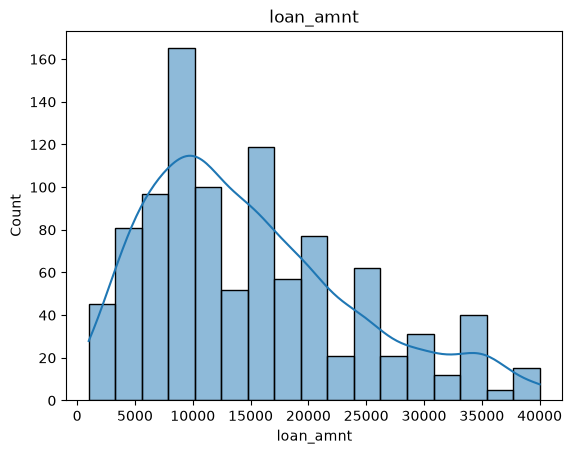

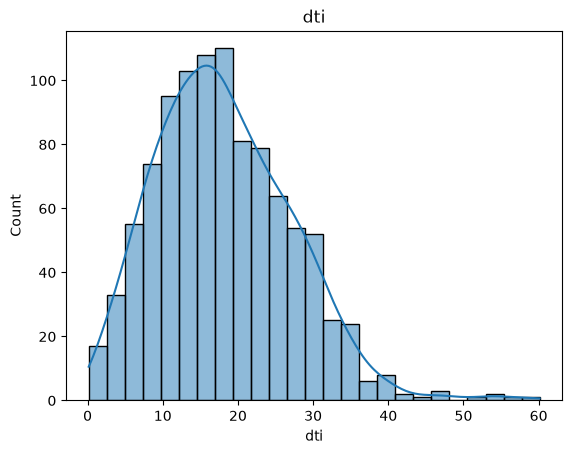

In [20]:
for col in important_num_cols:
    sns.histplot(df_eda[col], kde=True)
    plt.title(col)
    plt.show()

    - Boxplot (đối với numerical)

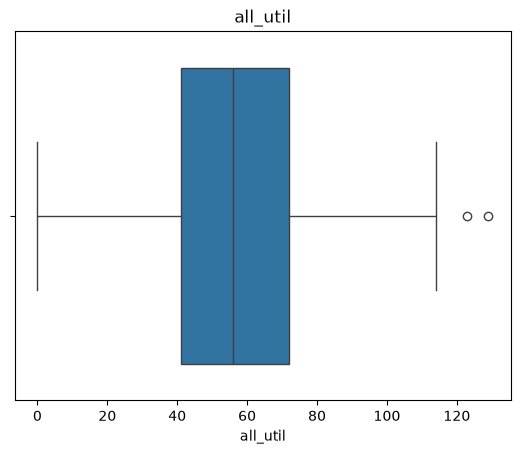

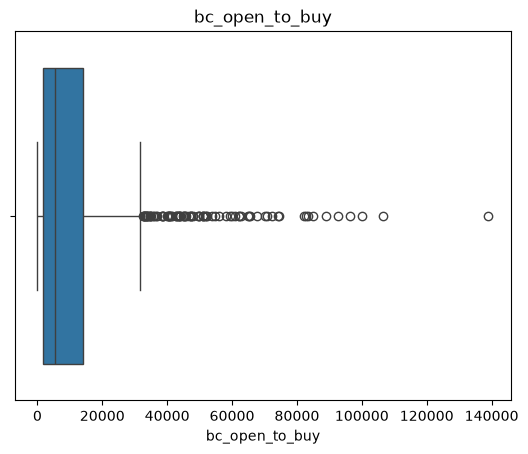

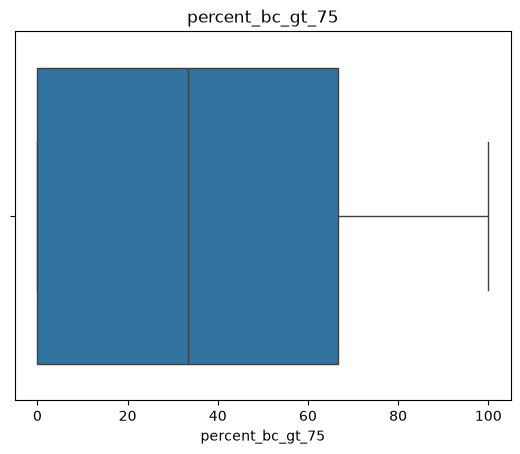

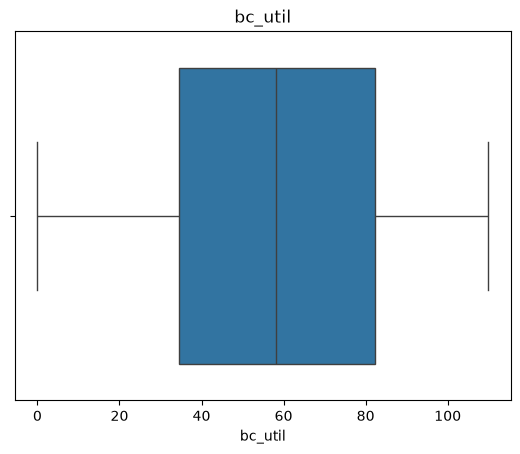

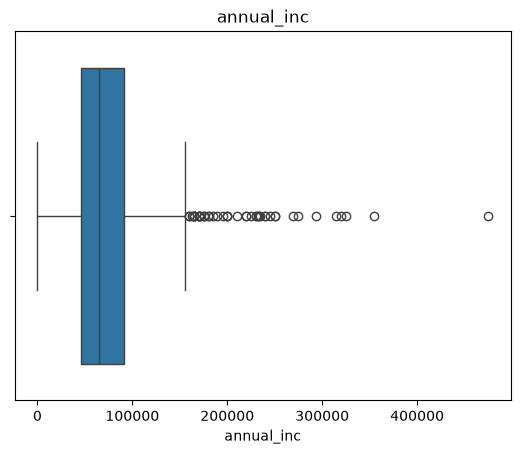

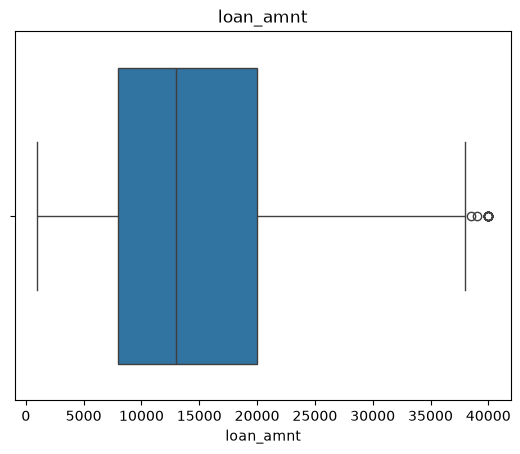

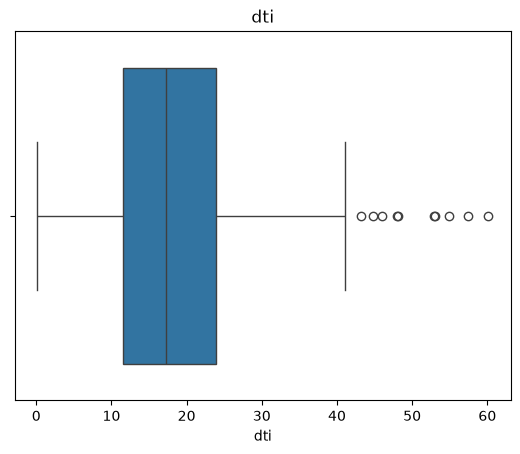

In [21]:
for col in important_num_cols:
    sns.boxplot(x=df_eda[col])
    plt.title(col)
    plt.show()

##### 10. Phân tích các cột `categorical`

In [22]:
for col in important_cat_cols:
    display(
        df_eda.groupby(col)["int_rate"]
              .mean()
              .sort_values()
    )

term
36 months    12.088718
60 months    16.214569
Name: int_rate, dtype: float64

grade
A     7.012043
B    10.721821
C    14.107417
D    18.061241
E    21.639403
F    25.390909
G    28.237143
Name: int_rate, dtype: float64

sub_grade
A1     5.513953
A2     6.599286
A3     7.030938
A4     7.513824
A5     8.202041
B1     9.182881
B2    10.030000
B3    10.680000
B4    11.474630
B5    12.055000
C1    12.764237
C2    13.477937
C3    14.143191
C4    14.881429
C5    15.862821
D1    16.665208
D2    17.464839
D3    18.627500
D4    18.922273
E1    19.589048
E2    20.162000
D5    20.362500
E4    23.173529
E5    23.295000
E3    23.321818
F3    24.065000
F1    24.155000
F2    25.410000
G4    25.990000
F5    26.963333
F4    26.976000
G2    27.310000
G1    28.295000
G3    28.390000
G5    30.990000
Name: int_rate, dtype: float64

verification_status
Not Verified       11.471576
Source Verified    13.377049
Verified           14.831792
Name: int_rate, dtype: float64

home_ownership
MORTGAGE    13.009455
RENT        13.273271
OWN         13.634167
Name: int_rate, dtype: float64

##### 11. Xử lý missing value

In [23]:
missing_stats = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_pct": round(df_eda.isna().mean() * 100, 2)
})

missing_stats = missing_stats.sort_values(
    by="missing_pct",
    ascending=False
)

display(missing_stats)

,missing_count,missing_pct
all_util,388,38.8
bc_open_to_buy,38,3.8
percent_bc_gt_75,38,3.8
bc_util,38,3.8
dti,1,0.1
annual_inc,0,0.0
loan_amnt,0,0.0
term,0,0.0
grade,0,0.0
sub_grade,0,0.0


Cột all_util thiếu khá nhiều, quan sát histogram và boxplot thấy được cột này có phân phối gần chuẩn và ít outlier, median cũng gần bằng mean nên dùng mean hay median đều hợp lý

Cột bc_open_to_buy, lệch phải nặng nên kh dùng mean

Cột percent_bc_gt_75 và bc_util, không chuẩn => dùng median cho an toàn

In [24]:
# all_util
df_eda["all_util"] = (
    df_eda["all_util"]
    .fillna(df_eda["all_util"].mean())
)

# các cột lệch hoặc có outlier
for col in [
    "bc_open_to_buy",
    "percent_bc_gt_75",
    "bc_util",
    "dti"
]:
    df_eda[col] = (
        df_eda[col]
        .fillna(df_eda[col].median())
    )

##### 12. Xử lý outlier

In [25]:
for col in important_num_cols:
    Q1 = df_eda[col].quantile(0.25)
    Q3 = df_eda[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_eda[
        (df_eda[col] < lower) |
        (df_eda[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} outliers "
        f"({round(len(outliers)/len(df_eda)*100,2)}%)"
    )

all_util: 211 outliers (21.1%)
bc_open_to_buy: 89 outliers (8.9%)
percent_bc_gt_75: 0 outliers (0.0%)
bc_util: 0 outliers (0.0%)
annual_inc: 46 outliers (4.6%)
loan_amnt: 14 outliers (1.4%)
dti: 10 outliers (1.0%)


Cột `all_util` có tỷ lệ outlier khá cao (21.1%) theo phương pháp IQR. Tuy nhiên khi quan sát histogram và boxplot, có thể thấy dữ liệu vẫn phân bố tương đối tự nhiên và không xuất hiện các giá trị bất thường về mặt nghiệp vụ. Do đó các outlier của cột này sẽ được giữ lại.

Các feature annual_inc và bc_open_to_buy có phân phối lệch phải và chứa nhiều giá trị lớn.

Sử dụng log transformation để giảm độ lệch của phân phối, giảm ảnh hưởng của outlier và giúp dữ liệu ổn định hơn cho mô hình.

Các cột `loan_amnt`, `dti`, `bc_util` và `percent_bc_gt_75` có số lượng outlier thấp hoặc không đáng kể, vì vậy không cần xử lý thêm ở bước này. 

In [26]:
import numpy as np

df_eda["bc_open_to_buy"] = np.log1p(
    df_eda["bc_open_to_buy"]
)

In [27]:
df_eda["annual_inc"] = np.log1p(
    df_eda["annual_inc"]
)

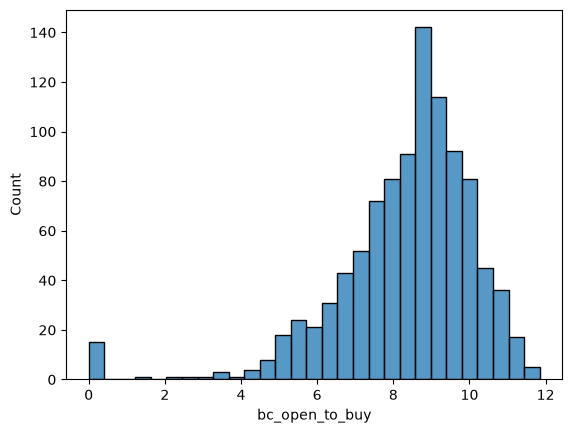

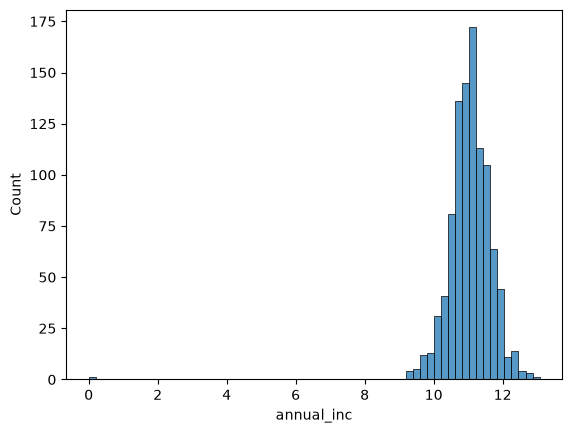

In [28]:
sns.histplot(df_eda["bc_open_to_buy"])
plt.show()

sns.histplot(df_eda["annual_inc"])
plt.show()

##### Save Preprocessed Dataset


In [29]:
df_eda.to_csv(
    "../data/loan_preprocessed.csv",
    index=False
)